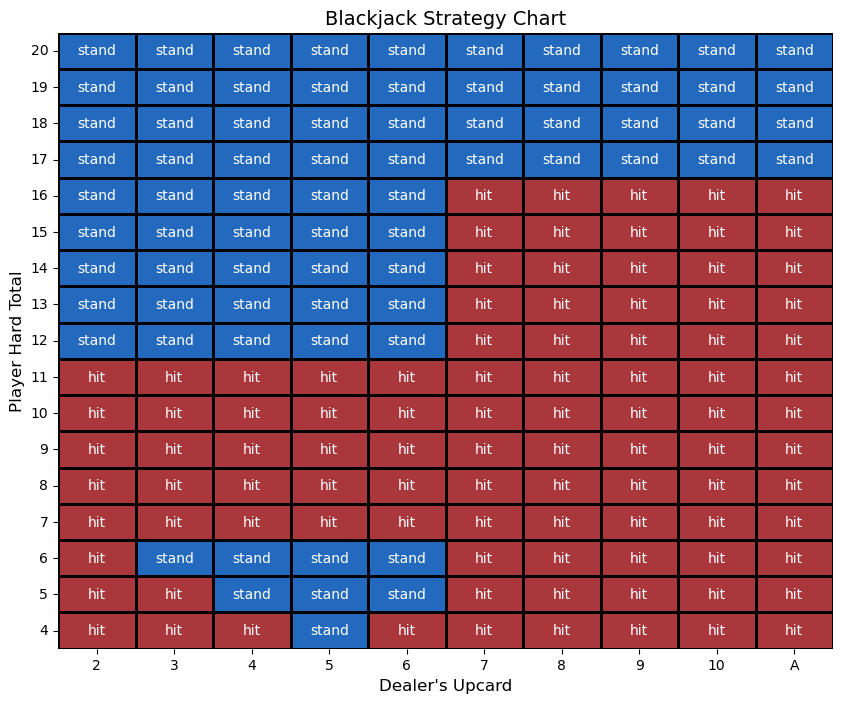

In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

results = pd.read_csv('/Users/nicholaskim/Documents/Repositories/black jack monte carlo/result_hardtotals.csv')

dealer_order = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'A']

strat = (
    results.pivot(index='hand_value', columns='dealer_show_value', values='best_action')
    [dealer_order]                      # columns: 2 ... A
    .sort_index(ascending=False)        # rows: 21 at the top down to 4, like printed charts
)

numeric = (strat == 'hit').astype(int)  # 1 = hit, 0 = stand

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    numeric,
    annot=strat,
    fmt='',
    cmap='vlag',
    cbar=False,
    linewidths=1,
    linecolor='black',
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel("Dealer's Upcard", fontsize=12)
ax.set_ylabel('Player Hard Total', fontsize=12)
ax.set_title('Blackjack Strategy Chart', fontsize=14)
plt.show()

In [8]:

diff_ordered = results.sort_values('hit_minus_stand', ascending=True)
diff_ordered.loc[diff_ordered['hit_minus_stand'] > 0,:]

,hand_value,dealer_show_value,hit_ev,stand_ev,hit_minus_stand,diff_se,hit_win,hit_tie,hit_loss,stand_win,stand_tie,stand_loss,best_action,significant
118,15,10,-0.4392,-0.4495,0.0103,0.010242,0.2570,0.0468,0.6962,0.2374,0.0757,0.6869,hit,False
92,13,4,0.1546,0.1313,0.0233,0.013428,0.5592,0.0362,0.4046,0.5280,0.0753,0.3967,hit,False
106,14,8,-0.1992,-0.2884,0.0892,0.011859,0.3777,0.0454,0.5769,0.3170,0.0776,0.6054,hit,True
93,13,5,0.0948,-0.0148,0.1096,0.012949,0.5289,0.0370,0.4341,0.4552,0.0748,0.4700,hit,True
109,14,A,-0.4906,-0.6503,0.1597,0.009273,0.2361,0.0372,0.7267,0.1338,0.0821,0.7841,hit,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21,6,3,0.5447,-0.7919,1.3366,0.008754,0.7415,0.0617,0.1968,0.0747,0.0587,0.8666,hit,True
11,5,3,0.4146,-0.9236,1.3382,0.008630,0.6750,0.0646,0.2604,0.0000,0.0764,0.9236,hit,True
10,5,2,0.5313,-0.8086,1.3399,0.008650,0.7360,0.0593,0.2047,0.0572,0.0770,0.8658,hit,True
22,6,4,0.4165,-0.9260,1.3425,0.008632,0.6764,0.0637,0.2599,0.0000,0.0740,0.9260,hit,True


In [41]:
results.loc[(results['hand_value']==6),:]

,hand_value,dealer_show_value,hit_ev,stand_ev,hit_minus_stand,diff_se,hit_win,hit_tie,hit_loss,stand_win,stand_tie,stand_loss,best_action,significant
20,6,2,-0.2815,-0.2830,0.0015,0.013757,0.3253,0.0679,0.6068,0.3585,0.0,0.6415,hit,False
21,6,3,-0.2638,-0.2390,-0.0248,0.013771,0.3345,0.0672,0.5983,0.3805,0.0,0.6195,stand,False
22,6,4,-0.2634,-0.1722,-0.0912,0.014077,0.3387,0.0592,0.6021,0.4139,0.0,0.5861,stand,True
23,6,5,-0.2313,-0.0842,-0.1471,0.014076,0.3543,0.0601,0.5856,0.4579,0.0,0.5421,stand,True
24,6,6,-0.1974,-0.1108,-0.0866,0.014150,0.3713,0.0600,0.5687,0.4446,0.0,0.5554,stand,True
25,6,7,-0.1568,-0.4552,0.2984,0.013077,0.3715,0.1002,0.5283,0.2724,0.0,0.7276,hit,True
26,6,8,-0.2675,-0.5200,0.2525,0.012418,0.3232,0.0861,0.5907,0.2400,0.0,0.7600,hit,True
27,6,9,-0.3257,-0.5544,0.2287,0.011943,0.2919,0.0905,0.6176,0.2228,0.0,0.7772,hit,True
28,6,10,-0.4006,-0.5838,0.1832,0.011519,0.2598,0.0798,0.6604,0.2081,0.0,0.7919,hit,True
29,6,A,-0.5609,-0.7676,0.2067,0.010658,0.1889,0.0613,0.7498,0.1162,0.0,0.8838,hit,True


In [ ]:
import random 
import pandas as pd
import numpy as np

from itertools import combinations

deck_suits = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
deck_ranks = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K', 'A']

pt_values = {'2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, '10': 10,'J': 10, 'Q': 10, 'K': 10, 'A': [1, 11]}

deck = [[suit, rank] for suit in deck_suits for rank in deck_ranks]

all_pairs = list(combinations(deck, 2))

def calculate_pt(hand, hard_total=True):
    
    if hard_total:
        pt = sum(1 if rank == 'A' else pt_values[rank] for _, rank in hand)
        has_ace = any(rank == 'A' for _, rank in hand)
        if has_ace and pt + 10 <= 21:   # promote one ace to 11 if it doesn't bust
            pt += 10
    else:
        pt = sum(1 if rank == 'A' else pt_values[rank] for _, rank in hand)
    return pt

def make_deck(*hands):
    used = [card for hand in hands for card in hand]
    return [card for card in deck if card not in used]


def card_val(card):
    return 11 if card[1] == 'A' else pt_values[card[1]]

#randomly draws two cards that add up to some value (the total value of your hand)
def draw_hand(value, hard_total=True):
    # hard: no ace in hand; soft: contains an ace
    choices = [list(p) for p in all_pairs
               if calculate_pt(list(p)) == value
               and any(r == 'A' for _, r in p) == (not hard_total)]
    return random.choice(choices)
        
#realized the logic for delear is easier
def draw_dealer(deck, up):
    up_val = 11 if up == 'A' else up
    rand_up = random.choice([c for c in deck if card_val(c) == up_val])
    hole = random.choice([c for c in deck if c != rand_up])
    return [rand_up, hole]

def compare_hands(you, dealer):
    if you > 21:
        return -1
    if dealer > 21 or you > dealer:
        return 1
    return 0 if you == dealer else -1

def play_dealer(dealer, deck):
    hand = list(dealer)
    
    #if hand value is < 17 then dealer forced to hit
    while calculate_pt(hand) < 17:
        hand.append(deck.pop())
    
    return calculate_pt(hand)

def simulate_deck(your_hand_value, dealer_up, hard_total=True):
    #return outcome under hit and stand under same situation
    
    your_hand = draw_hand(your_hand_value)

    dealer_hand = draw_dealer(make_deck(your_hand), dealer_up)    
    fil_deck = make_deck(your_hand, dealer_hand)
    random.shuffle(fil_deck)

    your_val = calculate_pt(your_hand, hard_total)
    dealer_val = calculate_pt(dealer_hand, hard_total)

    # blackjack check
    if your_val == 21 and dealer_val == 21:
        return 0, 0
    if your_val == 21:
        return 1, 1
    if dealer_val == 21:
        return -1, -1

    stand_outcome = compare_hands(your_val, play_dealer(dealer_hand, fil_deck.copy()))
    print(your_hand, dealer_hand)

    hit_outcome = 0
    
    hit_deck = fil_deck.copy()
    
    hit_hand = your_hand + [hit_deck.pop()]
    
    while calculate_pt(hit_hand) < 17:
        hit_hand.append(hit_deck.pop())
    
    your_val = calculate_pt(hit_hand)
    
    if your_val > 21:
        hit_outcome = -1
    else:
        hit_outcome = compare_hands(your_val, play_dealer(dealer_hand, hit_deck))
    
    print(hit_hand, dealer_hand)

    
    return hit_outcome, stand_outcome

def monte_carlo(num_sims, your_hand_value, dealer_up, hard_total = True):

    outcomes = np.array([simulate_deck(your_hand_value, dealer_up, hard_total) for _ in range(num_sims)])
    hits, stands = outcomes[:, 0], outcomes[:, 1]
    
    diff = hits - stands
    
    diff_mean = diff.mean()
    diff_se = diff.std(ddof=1) / np.sqrt(num_sims)

    return {
        'hand_value': your_hand_value,
        'dealer_show_value': dealer_up,
        'hit_ev': hits.mean(),
        'stand_ev': stands.mean(),
        'hit_minus_stand': diff_mean,
        'diff_se': diff_se,
        'hit_win': (hits == 1).mean(), 'hit_tie': (hits == 0).mean(), 'hit_loss': (hits == -1).mean(),
        'stand_win': (stands == 1).mean(), 'stand_tie': (stands == 0).mean(), 'stand_loss': (stands == -1).mean(),
        'best_action': 'hit' if hits.mean() > stands.mean() else 'stand',
        'significant': np.abs(diff_mean) > 2 * diff_se
    }


In [44]:
monte_carlo(1000, 6, 3)

{'hand_value': 6,
 'dealer_show_value': 3,
 'hit_ev': -0.279,
 'stand_ev': -0.234,
 'hit_minus_stand': -0.045,
 'diff_se': 0.0430677353691813,
 'hit_win': 0.323,
 'hit_tie': 0.075,
 'hit_loss': 0.602,
 'stand_win': 0.383,
 'stand_tie': 0.0,
 'stand_loss': 0.617,
 'best_action': 'stand',
 'significant': False}